# 07_expE_fast_sigmoid

Thí nghiệm E — Kiểm chứng "sigmoid nhanh" của posit es = 0 ([05] công thức (3), [21], [40]).

Với posit⟨n,0⟩ có mẫu bit X (số nguyên không dấu n bit):
    sigmoid_fast(X) = (X XOR 2^(n-1)) >> 2        (đảo bit dấu rồi dịch phải logic 2 bit)
Kết quả là MẪU BIT của một posit⟨n,0⟩ xấp xỉ 1/(1+e^-x). Chỉ cần 2 phép toán trên số nguyên.
Từ đó tanh_fast(x) = 2·sigmoid_fast(2x) − 1, kèm hiệu chỉnh của [40]: nếu |R| > θ=0.76 thì
cộng/trừ δ=0.068 (giới hạn ±1). [40] báo cáo trên [0, 8] với posit(16,0): sai số tuyệt đối
lớn nhất 0.098 → 0.0379 sau hiệu chỉnh; trung bình 0.056 → 0.0086.

## Mục tiêu và cách đọc

So sánh sigmoid/tanh xấp xỉ với hàm chuẩn. max_abs_err là sai số tuyệt đối lớn nhất, không phải phần trăm accuracy. Không đo tăng tốc phần cứng.

## Cách sử dụng

1. Chọn kernel Python có `ipykernel`, `numpy`, `torch`, `matplotlib`.
2. Giữ `RUN_EXPERIMENT = False` và chọn **Run All** để xem dữ liệu sẵn có.
3. Đổi thành `True` nếu muốn thực hiện lại; chạy tuần tự các ô từ đầu.
4. **Ctrl+S / Cmd+S** lưu toàn bộ output vào notebook. Báo cáo HTML và CSV được xuất tự động ở ô cuối.

**Lưu ý:** các hình B/C/D là file đã lưu; sau khi đổi kết quả, chạy notebook 08 để vẽ lại trước khi dùng hình trong bài. Thời điểm xuất báo cáo không phải thời điểm thực hiện thí nghiệm gốc.


## 1. Thiết lập và chọn chế độ

Cài môi trường một lần theo `HUONG_DAN_NOTEBOOK.md`. Mỗi lần chạy tạo thư mục riêng trong `results/notebook_runs/`. Khi chạy lại thí nghiệm, các kết quả chuẩn và checkpoint hiện có được sao lưu trước.

In [ ]:
from pathlib import Path
import os
import sys

# Tìm 02_demo dù kernel bắt đầu ở thư mục workspace hoặc thư mục notebook.
candidates = [Path.cwd(), *Path.cwd().parents]
DEMO_ROOT = next((base / suffix for base in candidates
                  for suffix in ("", "02_demo", "Gk_XLDL/02_demo")
                  if (base / suffix / "posit_lab/numformats.py").is_file()), None)
if DEMO_ROOT is None:
    raise FileNotFoundError("Mở notebook trong workspace chứa Gk_XLDL/02_demo.")
DEMO_ROOT = DEMO_ROOT.resolve()
os.chdir(DEMO_ROOT)
if str(DEMO_ROOT) not in sys.path:
    sys.path.insert(0, str(DEMO_ROOT))
from notebook_tools.reporting import NotebookRun

# False: xem số liệu sẵn có. True: chạy code thí nghiệm bên dưới.
RUN_EXPERIMENT = False
SCRIPT_ARGS = []
__file__ = str(DEMO_ROOT / '07_expE_fast_sigmoid.py')
__package__ = None
session = NotebookRun(DEMO_ROOT, '07_expE_fast_sigmoid.py', RUN_EXPERIMENT, SCRIPT_ARGS)
print("Thư mục lưu lần này:", session.out)

# Cell magic giữ code thẳng hàng; vẫn áp dụng chế độ chạy và lưu nhật ký.
from IPython.core.magic import register_cell_magic
import __future__

@register_cell_magic
def experiment(line, cell):
    if not RUN_EXPERIMENT:
        print("Đã bỏ qua tính toán; đặt RUN_EXPERIMENT = True để chạy ô này.")
        return
    with session.execute():
        code = compile(cell, str(session.source), "exec",
                       flags=__future__.annotations.compiler_flag)
        exec(code, get_ipython().user_ns)


## 2. encode_bits, fast_sigmoid_bits

Mã chuyển nguyên từ `07_expE_fast_sigmoid.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
"""
Thí nghiệm E — Kiểm chứng "sigmoid nhanh" của posit es = 0 ([05] công thức (3), [21], [40]).

Với posit⟨n,0⟩ có mẫu bit X (số nguyên không dấu n bit):
    sigmoid_fast(X) = (X XOR 2^(n-1)) >> 2        (đảo bit dấu rồi dịch phải logic 2 bit)
Kết quả là MẪU BIT của một posit⟨n,0⟩ xấp xỉ 1/(1+e^-x). Chỉ cần 2 phép toán trên số nguyên.
Từ đó tanh_fast(x) = 2·sigmoid_fast(2x) − 1, kèm hiệu chỉnh của [40]: nếu |R| > θ=0.76 thì
cộng/trừ δ=0.068 (giới hạn ±1). [40] báo cáo trên [0, 8] với posit(16,0): sai số tuyệt đối
lớn nhất 0.098 → 0.0379 sau hiệu chỉnh; trung bình 0.056 → 0.0086.
"""
import json
import os

import numpy as np
import torch

from posit_lab.numformats import decode_posit, quantize_posit
from posit_lab.plotstyle import setup, plt, C, INK2, MUTED

HERE = os.path.dirname(os.path.abspath(__file__))
RES, FIG = os.path.join(HERE, "results"), os.path.join(HERE, "figures")
setup()


def encode_bits(v, n, es=0):
    """Giá trị (đã là posit) -> mẫu bit, bằng tra bảng toàn bộ mẫu bit."""
    table = {decode_posit(p, n, es): p for p in range(1 << n) if p != 1 << (n - 1)}
    return np.array([table[float(x)] for x in v])


def fast_sigmoid_bits(bits, n):
    return ((bits ^ (1 << (n - 1))) & ((1 << n) - 1)) >> 2


out = {}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for n, ax in [(8, axes[0]), (16, axes[1])]:
    pats = np.array([p for p in range(1 << n) if p != 1 << (n - 1)])
    x = np.array([decode_posit(int(p), n, 0) for p in pats])
    y = np.array([decode_posit(int(b), n, 0) for b in fast_sigmoid_bits(pats, n)])
    true = 1 / (1 + np.exp(-x))
    err = np.abs(y - true)
    mask8 = np.abs(x) <= 8
    out[f"posit<{n},0> sigmoid"] = {"num_patterns": int(len(pats)),
                                    "max_abs_err_all": float(err.max()),
                                    "max_abs_err_|x|<=8": float(err[mask8].max()),
                                    "mean_abs_err_|x|<=8": float(err[mask8].mean())}
    o = np.argsort(x)
    sel = (x[o] >= -8) & (x[o] <= 8)
    ax.plot(x[o][sel], true[o][sel], color=C["blue"], lw=2, label="σ(x) = 1/(1+e⁻ˣ) chính xác")
    ax.plot(x[o][sel], y[o][sel], color=C["orange"], lw=1.4, ls="--", label="(X ⊕ 2ⁿ⁻¹) >> 2")
    ax.set_title(f"posit⟨{n},0⟩: sai số lớn nhất {err[mask8].max():.4f} trên [−8, 8]", loc="left",
                 fontsize=10)
    ax.set_xlabel("x")
    ax.legend(fontsize=8, loc="upper left")


## 3. Chuẩn bị / tính toán / lưu dữ liệu theo thứ tự script

Mã chuyển nguyên từ `07_expE_fast_sigmoid.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
axes[0].set_ylabel("sigmoid(x)")
fig.tight_layout()
fig.savefig(os.path.join(FIG, "E_fast_sigmoid.png"))

# ---- tanh theo [40]: posit(16,0), x trong [0, 8]
n = 16
pats = np.array([p for p in range(1 << n) if p != 1 << (n - 1)])
x_all = np.array([decode_posit(int(p), n, 0) for p in pats])
x = x_all[(x_all >= 0) & (x_all <= 8)]
two_x = quantize_posit(torch.from_numpy(2 * x), 16, 0).numpy()
sig = np.array([decode_posit(int(b), n, 0) for b in fast_sigmoid_bits(encode_bits(two_x, n), n)])
R = quantize_posit(torch.from_numpy(2 * sig - 1), 16, 0).numpy()
Rc = np.where(R > 0.76, np.minimum(R + 0.068, 1.0), np.where(R < -0.76, np.maximum(R - 0.068, -1.0), R))
te = np.abs(R - np.tanh(x)); tc = np.abs(Rc - np.tanh(x))
out["posit<16,0> tanh [40] on [0,8]"] = {
    "max_abs_err": float(te.max()), "mean_abs_err": float(te.mean()),
    "max_abs_err_corrected": float(tc.max()), "mean_abs_err_corrected": float(tc.mean()),
    "paper_reported": {"max": 0.098, "mean": 0.056, "max_corrected": 0.0379, "mean_corrected": 0.0086}}
with open(os.path.join(RES, "07_expE_fast_sigmoid.json"), "w") as f:
    json.dump(out, f, indent=1, ensure_ascii=False)
for k, v in out.items():
    print(k, v)
print("-> figures/E_fast_sigmoid.png")


## Kết quả, bảng số liệu và hình

Ô cuối đọc đầy đủ các trường JSON, xuất CSV UTF-8 cho Excel, lưu JSON gốc, nhúng hình vào HTML để mở độc lập. Các bảng dài có thanh cuộn. Khi viết bài, ghi rõ cấu hình, seed, tập dữ liệu và giới hạn mô phỏng.

metric,value
num_patterns,255
max_abs_err_all,0.060664021611295804
max_abs_err_|x|<=8,0.060664021611295804
mean_abs_err_|x|<=8,0.014864892330198717
metric,value
num_patterns,65535
max_abs_err_all,0.049000311288352916
max_abs_err_|x|<=8,0.049000311288352916
mean_abs_err_|x|<=8,0.012546871448034834
metric,value

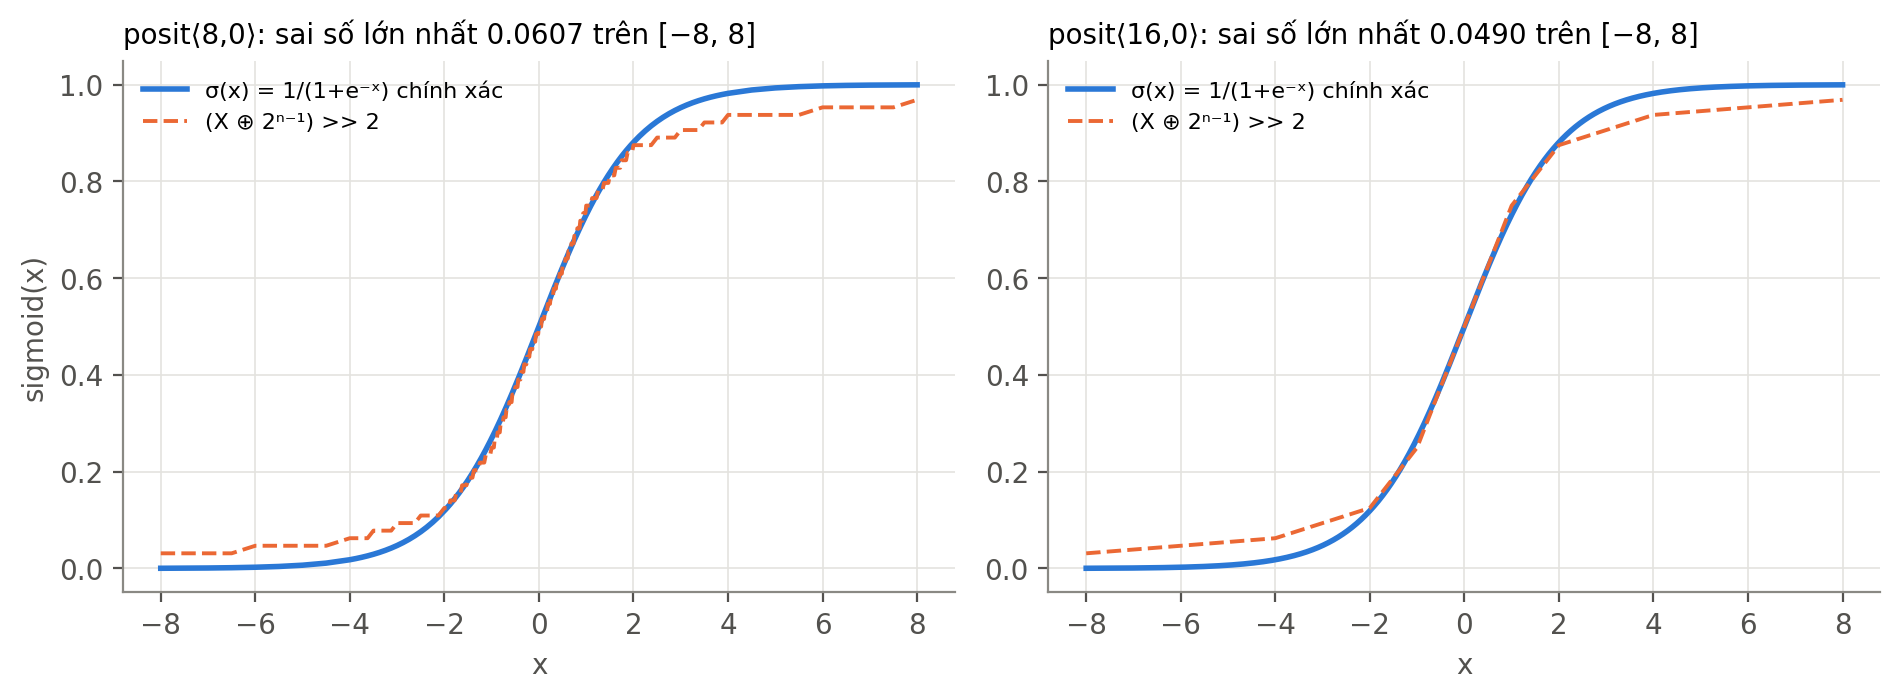

In [ ]:
session.report(['07_expE_fast_sigmoid.json'], ['E_*.png'])